In [1]:
import pandas as pd 
import numpy as np
import joblib
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.metrics import average_precision_score, brier_score_loss,roc_auc_score
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.calibration import CalibrationDisplay
import matplotlib.pyplot as plt

In [2]:
analysis_sample = pd.read_parquet('../data/processed/analysis_sample.parquet')
X = analysis_sample.drop(['id', 'exam_weight', 'survey_psu', 'survey_strata', 'weight', 'height', 'undiagnosed_diabetes'], axis=1)
y = analysis_sample['undiagnosed_diabetes']

features_a = X.columns.difference(['total_chol', 'hdl_chol']).to_list()
features_b = features_a + ['total_chol', 'hdl_chol']

num_cols = X.select_dtypes(include=['int', 'float']).columns.to_list()
bool_cols = X.select_dtypes(include='boolean').columns.to_list()
cat_cols = X.select_dtypes(include='category').columns.to_list()

X[bool_cols] = X[bool_cols].astype('float')

dropped = ['examination_period', 'years_in_us', 'language_of_interview', 'interpreter_used', 'income_to_poverty_ratio', 'marital_status']
separate_measure = ['systolic_bp', 'diastolic_bp', 'total_chol', 'hdl_chol']

lab_features = [x for x in features_b if x not in dropped]
basic_features = [f for f in lab_features if f not in separate_measure]

print(lab_features)
print(basic_features)

X_train, X_test, y_train, y_test = train_test_split(
    X,y, random_state=42, test_size=0.2, stratify=y
)

['active_leisure', 'age_at_screening', 'birth_place', 'bmi', 'diastolic_bp', 'family_history_diabetes', 'level_of_education', 'race', 'sex', 'smoking_status', 'systolic_bp', 'takes_bp_meds', 'takes_chol_meds', 'told_high_bp', 'told_high_chol', 'waist_circ', 'total_chol', 'hdl_chol']
['active_leisure', 'age_at_screening', 'birth_place', 'bmi', 'family_history_diabetes', 'level_of_education', 'race', 'sex', 'smoking_status', 'takes_bp_meds', 'takes_chol_meds', 'told_high_bp', 'told_high_chol', 'waist_circ']


In [3]:
def make_preprocessor(features):
    num = [col for col in num_cols if col in features]
    bool_ = [col for col in bool_cols if col in features]
    cats = [col for col in cat_cols if col in features]
    num_pipeline = Pipeline([('med_imp', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
    bool_pipeline = Pipeline([('freq_imp', SimpleImputer(strategy='most_frequent'))])
    cat_pipeline = Pipeline([('cat_imp', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    
    preprocessor = ColumnTransformer([
                                ('num', num_pipeline, num), 
                                ('bool', bool_pipeline, bool_),
                                ('cat', cat_pipeline, cats)
                                ])
    return preprocessor

In [4]:
full_model = Pipeline([('prep', make_preprocessor(features_b)), ('clf', LogisticRegression(max_iter=1000))])
lab_model = Pipeline([('prep', make_preprocessor(lab_features)), ('clf', LogisticRegression(max_iter=1000))])
basic_model = Pipeline([('prep', make_preprocessor(basic_features)), ('clf', LogisticRegression(max_iter=1000))])

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

models = {
    'full_model' : [full_model, features_b],
    'lab_model' : [lab_model, lab_features],
    'basic_model' : [basic_model, basic_features]
}

for name, values in models.items():
    model = values[0]
    feat = values[1]
    scores = cross_validate(model, X_train[feat], y_train, cv=cv, scoring=['roc_auc', 'average_precision'])
    cv_results[name] = {
        'ROC-AUC mean' : scores['test_roc_auc'].mean(),
        'ROC-AUC std' : scores['test_roc_auc'].std(),
        'PR-AUC mean' : scores['test_average_precision'].mean(),
        'PR-AUC std' : scores['test_average_precision'].std()
    }
cv_results_df = pd.DataFrame(cv_results).T
display(cv_results_df)

,ROC-AUC mean,ROC-AUC std,PR-AUC mean,PR-AUC std
full_model,0.796580,0.029320,0.119882,0.042697
lab_model,0.799620,0.026803,0.122565,0.038190
basic_model,0.767954,0.033198,0.101980,0.027684


In [6]:
test_results = {}
for name, values in models.items():
    model = values[0]
    feat = values[1]
    model.fit(X_train[feat], y_train)
    pred = model.predict_proba(X_test[feat])[:, 1] 

    roc_score = roc_auc_score(y_test, pred)
    avg_pr_score = average_precision_score(y_test, pred)
    brier = brier_score_loss(y_test, pred)
    test_results[name] = {
        'ROC-AUC' : roc_score,
        'PR-AUC' : avg_pr_score,
        'Brier' : brier        
    }

test_df = pd.DataFrame.from_dict(test_results, orient='index')
display(test_df.round(3))

,ROC-AUC,PR-AUC,Brier
full_model,0.828,0.141,0.032
lab_model,0.830,0.149,0.032
basic_model,0.812,0.098,0.033


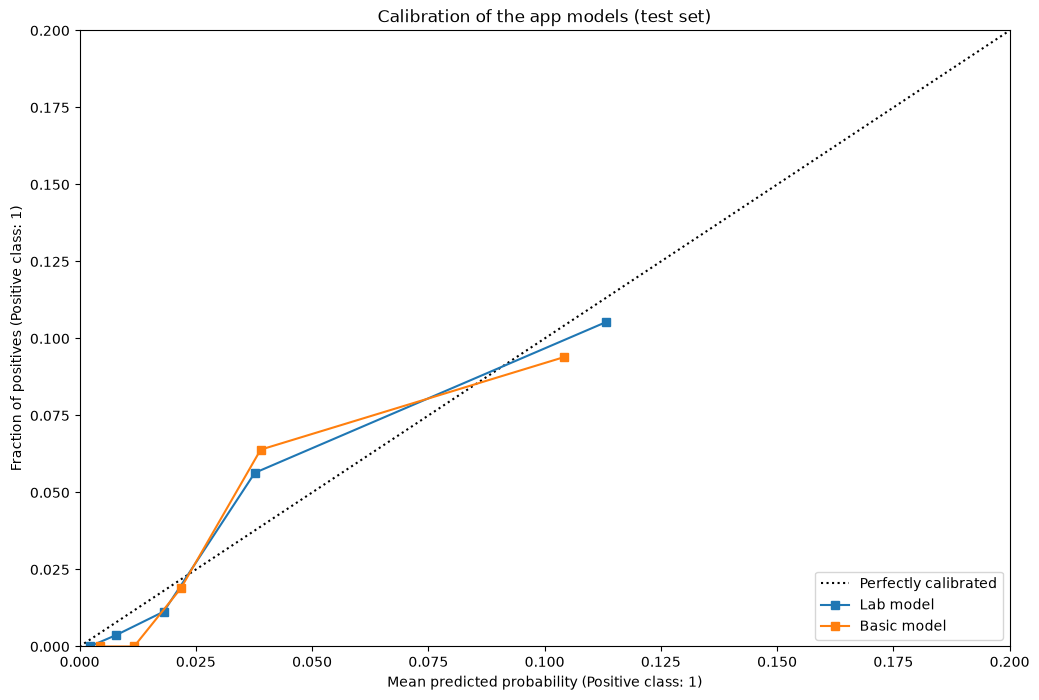

In [7]:
fig, ax = plt.subplots(figsize=(12,8))

lab_proba = lab_model.predict_proba(X_test[lab_features])[:, 1]
basic_proba = basic_model.predict_proba(X_test[basic_features])[:,1]

lab_disp =  CalibrationDisplay.from_predictions(y_test, lab_proba, n_bins=5, strategy='quantile', name='Lab model', ax=ax)
basic_disp = CalibrationDisplay.from_predictions(y_test, basic_proba, n_bins=5, strategy='quantile', name='Basic model', ax=ax)

ax.set_xlim(0, 0.2)
ax.set_ylim(0,0.2)

ax.set_title('Calibration of the app models (test set)')
fig.savefig('../reports/figures/calibration_app_models.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
lab_model.fit(X[lab_features], y)
basic_model.fit(X[basic_features], y)

joblib.dump(lab_model, '../models/lab_model.joblib')
joblib.dump(basic_model, '../models/basic_model.joblib')

['../models/basic_model.joblib']

In [10]:
loaded = joblib.load('../models/lab_model.joblib')

assert np.allclose(loaded.predict_proba(X[lab_features].head(10)), lab_model.predict_proba(X[lab_features].head(10)))